In [85]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import scipy
import math
from scipy.linalg import expm
import networkx as nx

from pymoo.core.problem import Problem, ElementwiseProblem
from pymoo.algorithms.soo.nonconvex.ga import GA
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize
from pymoo.operators.sampling.rnd import FloatRandomSampling
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.visualization.scatter import Scatter

from notears.linear import notears_linear 

In [86]:
LAMBDA = 0.1
seed = np.random.randint(0, 100)

In [87]:
def generate_sem(n, adj_matrix, noise="gaussian", seed=seed,
                 coef_range=(1, 2.5)):
    
    rng = np.random.default_rng(seed)
    
    adj_matrix = np.asarray(adj_matrix)
    
    # --------------------------------------------------
    # Validações
    # --------------------------------------------------
    if adj_matrix.ndim != 2:
        raise ValueError("adj_matrix deve ser uma matriz 2D.")
    
    if adj_matrix.shape[0] != adj_matrix.shape[1]:
        raise ValueError("adj_matrix deve ser quadrada.")
    
    if not np.all(np.isin(adj_matrix, [0, 1])):
        raise ValueError("adj_matrix deve conter apenas 0 e 1.")
    
    d = adj_matrix.shape[0]
    
    # --------------------------------------------------
    # Verifica se o grafo é acíclico
    # --------------------------------------------------
    G = nx.DiGraph()
    
    for i in range(d):
        for j in range(d):
            if adj_matrix[i, j] == 1:
                G.add_edge(i, j)
    
    if not nx.is_directed_acyclic_graph(G):
        raise ValueError(
            "A matriz representa um grafo cíclico. "
            "Para um SEM causal, forneça um DAG."
        )
    
    # --------------------------------------------------
    # Matriz dos coeficientes
    # Mesma orientação da matriz de entrada:
    #
    # A[i,j] = 1  =>  Xi -> Xj
    # B[i,j] = coeficiente de Xi -> Xj
    # --------------------------------------------------
    coef_matrix = np.zeros((d, d))
    
    for i in range(d):
        for j in range(d):
            if adj_matrix[i, j] == 1:
                
                # Magnitude aleatória
                beta = rng.uniform(*coef_range)
                
                # Sinal aleatório
                beta *= rng.choice([-1, 1])
                
                coef_matrix[i, j] = beta
    
    # --------------------------------------------------
    # Geração dos dados na ordem topológica
    # --------------------------------------------------
    topological_order = list(nx.topological_sort(G))
    
    X = np.zeros((n, d))
    
    for j in topological_order:
        
        # Ruído da variável
        if noise == "gaussian":
            epsilon = rng.normal(size=n)
            
        elif noise == "laplace":
            epsilon = rng.laplace(size=n)
            
        else:
            raise ValueError(
                "noise deve ser 'gaussian' ou 'laplace'."
            )
        
        # Pais de Xj
        parents = np.where(adj_matrix[:, j] == 1)[0]
        
        # SEM linear
        X[:, j] = epsilon
        
        for i in parents:
            X[:, j] += coef_matrix[i, j] * X[:, i]
    
    # --------------------------------------------------
    # DataFrame
    # --------------------------------------------------
    columns = [f"X{i+1}" for i in range(d)]
    
    df = pd.DataFrame(X, columns=columns)
    
    return df, coef_matrix

In [88]:
A = np.array([
    [0, 1, 0, 0],
    [0, 0, 1, 1],
    [0, 0, 0, 1],
    [0, 0, 0, 0]
])

In [89]:
dataset, B = generate_sem(10000, A)
X = dataset.values
X = X - np.mean(X, axis=0, keepdims=True)
n = X.shape[0]
dim = X.shape[1]

print(B)

[[ 0.         -1.58154981  0.          0.        ]
 [ 0.          0.          1.77070082  2.04173786]
 [ 0.          0.          0.          2.29467521]
 [ 0.          0.          0.          0.        ]]


In [90]:
def acyclic_restriction(W):
    W = np.asarray(W).reshape(dim, dim)

    W_squared = W * W

    return np.trace(expm(W_squared)) - dim

def projection(W):
    W = np.asarray(W).reshape(dim, dim)
    
    R = X - X @ W

    reconstruction = (
            1 / (2 * n)
            * (R ** 2).sum()
        )

    return reconstruction

def l1_pen(W):
    W = np.asarray(W).reshape(dim, dim)

    return np.abs(W).sum()


def cost_function(W):
    W = np.asarray(W).reshape(dim, dim)

    return projection(W) + LAMBDA * l1_pen(W)


def augmented_lagrangian(W, rho, alpha):

    cost = cost_function(W)

    h = acyclic_restriction(W)

    return (
        cost
        + (rho / 2) * h**2
        + alpha * h
    )

In [91]:
upper_bounds = np.zeros((dim, dim))
upper_bounds.fill(3)
np.fill_diagonal(upper_bounds, 0)
upper_bounds = upper_bounds.reshape(-1)
lower_bounds = -1*upper_bounds

In [92]:
class NOTEARSLagrangianProblem(Problem):

    def __init__(self, rho, alpha):

        self.rho = rho
        self.alpha = alpha

        super().__init__(
            n_var=dim * dim,
            n_obj=1,
            xl=lower_bounds,
            xu=upper_bounds
        )

    def _evaluate(self, W, out, *args, **kwargs):

        F = np.zeros(len(W))

        for i in range(len(W)):

            F[i] = augmented_lagrangian(
                W[i],
                self.rho,
                self.alpha
            )

        out["F"] = F.reshape(-1, 1)

algorithm = GA(

    pop_size=100,

    crossover=SBX(
        prob=0.7,
        eta=20
    ),

    mutation=PM(
        prob=1.0,
        prob_var=1/(dim*dim),
        eta=15
    ),

    eliminate_duplicates=True
)

In [93]:
def bic_dag(W, X, thr=0.3):
    n, d = X.shape; S = np.abs(W) >= thr
    G = nx.from_numpy_array(S.astype(int), create_using=nx.DiGraph)
    if not nx.is_directed_acyclic_graph(G): return np.inf   # inviável
    tot = 0.0
    for j in range(d):
        pa = np.where(S[:, j])[0]
        r = X[:, j] if len(pa) == 0 else X[:, j] - X[:, pa] @ np.linalg.lstsq(X[:, pa], X[:, j], rcond=None)[0]
        tot += n*np.log((r**2).mean()) + len(pa)*np.log(n)
    return tot

In [94]:
rho = 1.0
alpha = 0.0
h = np.inf

rho_max = 10e10
h_tol = 1e-3
itermax = 100

W_est = None

h_previous = np.inf

best_bic, best_W = np.inf, None

for it in range(itermax):
    w_new, h_new = None, None
    print(f"\n===== Iteração externa {it + 1} =====")
    while rho < rho_max:
        problem = NOTEARSLagrangianProblem(rho=rho, alpha=alpha)
        
        res = minimize(
            problem,
            algorithm,
            termination=("n_gen", 500),
            sampling=W_est if W_est is not None else np.zeros(dim**2),
            seed=np.random.randint(100),
            verbose=False
        )

        w_new = res.X
        h_new = acyclic_restriction(w_new)
        objective = augmented_lagrangian(w_new, rho, alpha)

        print(f"Objetivo:       {objective:.8f}")
        print(f"h(W):           {h_new:.8f}")
        print(f"rho:            {rho:.4f}")
        print(f"alpha:          {alpha:.8f}")

        if h_new > 0.25 * h:
            rho *= 10
        else:
            break

    W_est, h = w_new, h_new
    alpha += rho * h

    b = bic_dag(W_est.reshape(dim, dim), X)
    if b <= best_bic:
        print('trocou')
        best_bic, best_W = b, W_est.copy()
    
    if h <= h_tol or rho >= rho_max:
        break


===== Iteração externa 1 =====
Objetivo:       1.48548137
h(W):           0.38177670
rho:            1.0000
alpha:          0.00000000
trocou

===== Iteração externa 2 =====
Objetivo:       1.61639975
h(W):           0.32730380
rho:            1.0000
alpha:          0.38177670
Objetivo:       1.82809978
h(W):           0.17179571
rho:            10.0000
alpha:          0.38177670
Objetivo:       2.09732120
h(W):           0.05398886
rho:            100.0000
alpha:          0.38177670
trocou

===== Iteração externa 3 =====
Objetivo:       2.31911624
h(W):           0.03218146
rho:            100.0000
alpha:          5.78066306
Objetivo:       2.46564565
h(W):           0.01231941
rho:            1000.0000
alpha:          5.78066306
trocou

===== Iteração externa 4 =====
Objetivo:       2.58012570
h(W):           0.00663931
rho:            1000.0000
alpha:          18.10007425
Objetivo:       2.68227847
h(W):           0.00283809
rho:            10000.0000
alpha:          18.10007425
tr

In [95]:
augmented_lagrangian(W_est, rho, alpha)

np.float64(2.780444723510033)

In [96]:
W_est[np.abs(W_est) < 0.3] = 0.0
W_est.reshape(dim, dim)

array([[ 0.        , -1.45562533,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  1.73050663,  1.59917133],
       [ 0.        ,  0.        ,  0.        ,  2.52460189],
       [ 0.        ,  0.        ,  0.        ,  0.        ]])

In [97]:
best_W = best_W.reshape(dim, dim)

In [98]:
class NOTEARS_multioo(ElementwiseProblem):
    def __init__(self) :
        super().__init__(
        n_var = dim**2,
        n_obj = 2,
        n_ieq_constr = 0,
        xl = lower_bounds,
        xu = upper_bounds
        )
    def _evaluate(self, x, out, *args, **kwargs) :
        f2 = l1_pen(x)
        f1 = projection(x) + LAMBDA * f2
        f3 = acyclic_restriction(x)

        out["F"] = [ f1, f3 ]

In [99]:
problema = NOTEARS_multioo()

algorithm = NSGA2(
    pop_size=100,

    sampling=FloatRandomSampling(),

    crossover=SBX(
        prob=0.6,
        eta=15
    ),

    mutation=PM(
        prob=1.0,
        prob_var=1/(dim*dim),
        eta=20
    ),

    eliminate_duplicates=True
)

In [100]:
res = minimize(problema,
               algorithm,
               ('n_gen', 1500),
               verbose=False,
               seed=np.random.randint(100),
               save_history=True)

In [101]:
notears_result = notears_linear(X, lambda1=0.1, loss_type='l2', w_threshold=-np.inf)

In [102]:
F = np.asarray(res.F, dtype=float)

# Escala de cada objetivo
scale = np.ptp(F, axis=0)

# Evitar divisão por zero quando um objetivo é constante
scale[scale == 0] = 1.0

# Normalização que preserva o ideal (0, 0)
F_norm = F / scale

# Distância normalizada ao ideal
distances = np.linalg.norm(F_norm, axis=1)

# Solução selecionada
idx = np.argmin(distances)

x_best = res.X[idx]
f_best = res.F[idx]

print("Índice:", idx)
print("Objetivos originais:", f_best)
print("Objetivos normalizados:", F_norm[idx])
print("Distância normalizada:", distances[idx])
print("Variáveis de decisão:", x_best)


Índice: 23
Objetivos originais: [2.7467714  0.00425712]
Objetivos normalizados: [0.03605907 0.00806015]
Distância normalizada: 0.03694892078806672
Variáveis de decisão: [ 0.00000000e+00 -8.72381110e-01 -1.01530232e-02 -8.06585692e-02
  3.49247508e-04  0.00000000e+00  1.59439828e+00  1.83550747e+00
 -6.38186984e-04 -1.12504822e-03  0.00000000e+00  2.38632436e+00
 -3.66278417e-02  5.28850078e-04  3.18596351e-03  0.00000000e+00]


In [103]:
f_best

array([2.7467714 , 0.00425712])

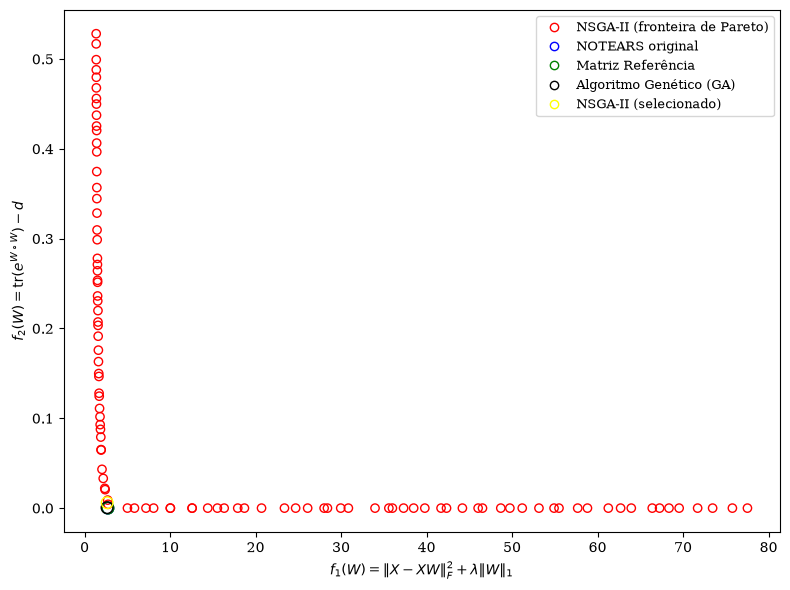

In [108]:

import numpy as np
import matplotlib.pyplot as plt
from pymoo.visualization.scatter import Scatter

axis_labels = [
    r"$f_1(W)=\|X-XW\|_F^2+\lambda\|W\|_1$",
    r"$f_2(W)=\operatorname{tr}(e^{W\circ W})-d$"
]

plot = Scatter(labels=axis_labels)

# Fronteira de Pareto
plot.add(
    res.F,
    facecolor="none",
    edgecolor="red"
)

# Pontos individuais
points = [
    (f_notears, "NOTEARS original", "blue"),
    (original, "Matriz Referência", "green"),
    (ga, "Algoritmo Genético (GA)", "black"),
    (nsgaii, "NSGA-II (selecionado)", "yellow"),
]

for point, label, color in points:
    plot.add(
        np.asarray(point).reshape(1, -1),
        facecolor="none",
        edgecolor=color,
        s=70
    )

# Renderiza o gráfico
plot.do()

# Recupera o eixo criado pelo pymoo e adiciona a legenda
ax = plt.gca()

# Cria marcadores para a legenda, independentemente dos objetos do pymoo
legend_handles = [
    plt.Line2D(
        [0], [0],
        color="red",
        marker="o",
        linestyle="none",
        markerfacecolor="none",
        label="NSGA-II (fronteira de Pareto)"
    ),
    plt.Line2D(
        [0], [0],
        color="blue",
        marker="o",
        linestyle="none",
        markerfacecolor="none",
        label="NOTEARS original"
    ),
    plt.Line2D(
        [0], [0],
        color="green",
        marker="o",
        linestyle="none",
        markerfacecolor="none",
        label="Matriz Referência"
    ),
    plt.Line2D(
        [0], [0],
        color="black",
        marker="o",
        linestyle="none",
        markerfacecolor="none",
        label="Algoritmo Genético (GA)"
    ),
    plt.Line2D(
        [0], [0],
        color="yellow",
        marker="o",
        linestyle="none",
        markerfacecolor="none",
        label="NSGA-II (selecionado)"
    ),
]

ax.legend(handles=legend_handles, loc="best", fontsize=9)
plt.tight_layout()
plt.show()
